# Problem Set 9 — Answer Key: Pricing Securities in a Finite-State Markov Economy

**Economics 5040: Dynamic Stochastic Modeling — Fall 2026**

This notebook accompanies Problem Set 10. The central pricing formula is

$$
p^{(T)}=Q^T r,
\qquad
Q_{ij}=P_{ij}\beta\left(\frac{c_j}{c_i}\right)^{-\rho}.
$$

Unless otherwise stated, use $\beta=0.97$, $\rho=2$,

$$
c=(0.5,1.0,1.5)',
$$

and

$$
P=
\begin{pmatrix}
0.80&0.15&0.05\\
0.10&0.80&0.10\\
0.05&0.15&0.80
\end{pmatrix}.
$$


In [9]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

beta = 0.97
rho = 2.0
c = np.array([0.5, 1.0, 1.5])
P = np.array([
    [0.80, 0.15, 0.05],
    [0.10, 0.80, 0.10],
    [0.05, 0.15, 0.80]
])

def sdf_matrix(rho, beta, c):
    c = np.asarray(c, dtype=float).reshape(-1)
    return beta * (c[None, :] / c[:, None])**(-rho)

def pricing_matrix(rho, beta, P, c):
    M = sdf_matrix(rho, beta, c)
    return M, P * M

M, Q = pricing_matrix(rho, beta, P, c)
M, Q


(array([[0.97    , 0.2425  , 0.107778],
        [3.88    , 0.97    , 0.431111],
        [8.73    , 2.1825  , 0.97    ]]),
 array([[0.776   , 0.036375, 0.005389],
        [0.388   , 0.776   , 0.043111],
        [0.4365  , 0.327375, 0.776   ]]))

## Problem 1 — Answer

For CRRA preferences $u'(c)=c^{-\rho}$, hence

$$
m_{ij}=\beta\frac{c_j^{-\rho}}{c_i^{-\rho}}
=\beta\left(\frac{c_j}{c_i}\right)^{-\rho}.
$$

The matrix $M$ contains marginal-utility discounting; $Q=P\circ M$ additionally incorporates the probability of each transition. Thus $Q_{ij}$ is the current-state-$i$ price of a one-period Arrow security paying one unit only if state $j$ occurs.


In [10]:
print("M =")
print(M)
print("\nQ =")
print(Q)

low_arrow = np.array([1.0, 0.0, 0.0])
print("\nOne-period low-state Arrow prices:")
print(Q @ low_arrow)


M =
[[0.97     0.2425   0.107778]
 [3.88     0.97     0.431111]
 [8.73     2.1825   0.97    ]]

Q =
[[0.776    0.036375 0.005389]
 [0.388    0.776    0.043111]
 [0.4365   0.327375 0.776   ]]

One-period low-state Arrow prices:
[0.776  0.388  0.4365]


A transition into low consumption has a high SDF when current consumption is higher because an extra unit of consumption is especially valuable in the low-consumption state. Notice that the same payoff therefore has different prices depending on today's state.


## Problem 2 — Answer


In [11]:
r = np.array([0.5, 1.0, 2.0])
r_tilde = np.array([2.0, 1.0, 0.5])

p = Q @ r
p_tilde = Q @ r_tilde

print("Price of r:      ", p)
print("Price of r_tilde:", p_tilde)


Price of r:       [0.435153 1.056222 2.097625]
Price of r_tilde: [1.591069 1.573556 1.588375]


The securities have the same unordered payoff amounts, but the second places its largest payoff in the low-consumption state. Such payoffs are valuable because they arrive when marginal utility is high. A payoff vector records units delivered by state; a **return** would relate future payoff to the asset's purchase price.


## Problem 3 — Answer


1 [0.776  0.388  0.4365]
2 [0.618642 0.620994 0.80447 ]
5 [0.368594 0.867538 1.483315]
10 [0.233583 0.831424 1.728509]
20 [0.156253 0.621367 1.390758]


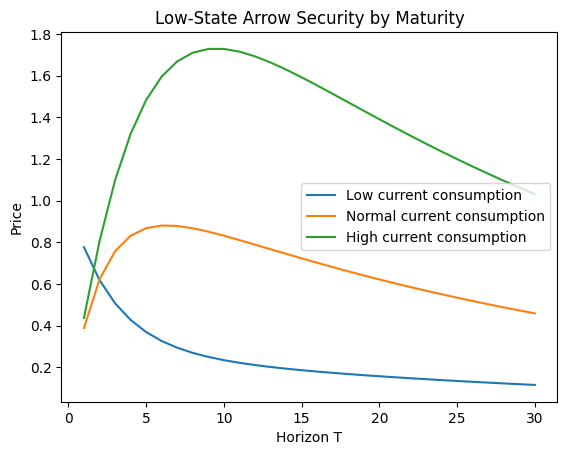

In [12]:
low_arrow = np.array([1.0, 0.0, 0.0])
horizons = [1, 2, 5, 10, 20]

for T in horizons:
    print(T, np.linalg.matrix_power(Q, T) @ low_arrow)

Ts = np.arange(1, 31)
price_path = np.array([np.linalg.matrix_power(Q, T) @ low_arrow for T in Ts])

for i, label in enumerate(["Low current consumption", "Normal current consumption", "High current consumption"]):
    plt.plot(Ts, price_path[:, i], label=label)
plt.xlabel("Horizon T")
plt.ylabel("Price")
plt.title("Low-State Arrow Security by Maturity")
plt.legend()
plt.show()


Repeated application of $Q$ integrates over every possible intermediate Markov path while applying marginal-utility discounting at each step. The initial state matters because it determines the first conditional distribution and the initial marginal utility against which future consumption is valued. With a mixing Markov chain, the direct influence of the initial state tends to weaken at long horizons, although state-dependent marginal utility still affects the level of current prices.


## Problem 4 — Answer


One-period bond prices: [0.817764 1.207111 1.539875]
Gross risk-free returns: [1.222847 0.828424 0.649403]


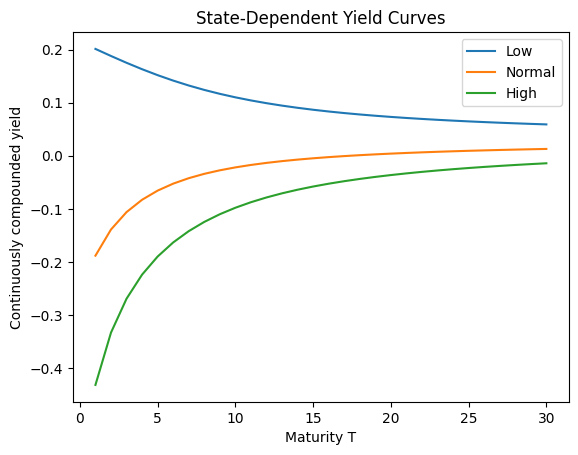

In [13]:
ones = np.ones(3)
b1 = Q @ ones
Rf = 1 / b1

print("One-period bond prices:", b1)
print("Gross risk-free returns:", Rf)

Ts = np.arange(1, 31)
bond_prices = np.array([np.linalg.matrix_power(Q, T) @ ones for T in Ts])
yields = -np.log(bond_prices) / Ts[:, None]

for i, label in enumerate(["Low", "Normal", "High"]):
    plt.plot(Ts, yields[:, i], label=label)
plt.xlabel("Maturity T")
plt.ylabel("Continuously compounded yield")
plt.title("State-Dependent Yield Curves")
plt.legend()
plt.show()


Numerically, the one-period bond prices are approximately $(0.817764,1.207111,1.539875)'$, giving gross risk-free returns $(1.222847,0.828424,0.649403)'$. The high-consumption current state has the lowest risk-free return in this calibration. Although the terminal payoff is certain, its current price depends on how the current state changes the distribution of future consumption and hence the marginal utility value of that certain future unit.


## Problem 5 — Answer


Five-period low-state Arrow prices:
[[   0.368594    0.216885    0.164813]
 [   0.368594    0.433769    0.494438]
 [   0.368594    0.867538    1.483315]
 [   0.368594    6.940306   40.049509]
 [   0.368594  222.089778 9732.030805]]

Five-period high-state Arrow prices:
[[0.164813 0.216885 0.368594]
 [0.054938 0.14459  0.368594]
 [0.018313 0.096393 0.368594]
 [0.000678 0.028561 0.368594]
 [0.000003 0.003761 0.368594]]


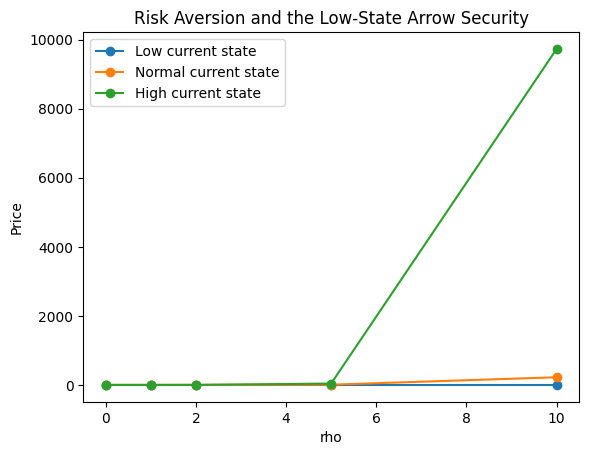

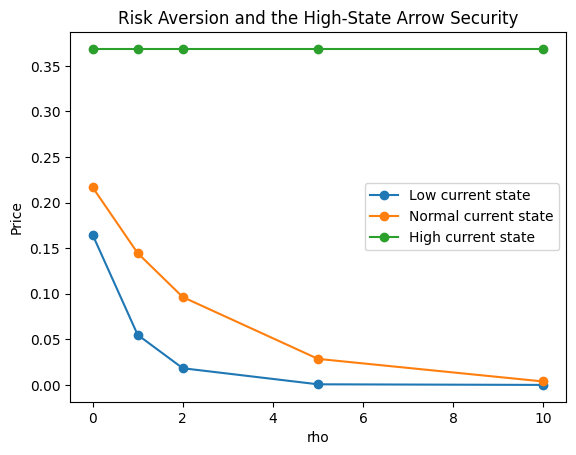

In [14]:
rho_values = [0, 1, 2, 5, 10]
low_arrow = np.array([1.0, 0.0, 0.0])
high_arrow = np.array([0.0, 0.0, 1.0])

low_prices = []
high_prices = []

for rr in rho_values:
    _, Qr = pricing_matrix(rr, beta, P, c)
    low_prices.append(np.linalg.matrix_power(Qr, 5) @ low_arrow)
    high_prices.append(np.linalg.matrix_power(Qr, 5) @ high_arrow)

low_prices = np.array(low_prices)
high_prices = np.array(high_prices)

print("Five-period low-state Arrow prices:")
print(low_prices)
print("\nFive-period high-state Arrow prices:")
print(high_prices)

for i, label in enumerate(["Low current state", "Normal current state", "High current state"]):
    plt.plot(rho_values, low_prices[:, i], marker="o", label=label)
plt.xlabel("rho")
plt.ylabel("Price")
plt.title("Risk Aversion and the Low-State Arrow Security")
plt.legend()
plt.show()

for i, label in enumerate(["Low current state", "Normal current state", "High current state"]):
    plt.plot(rho_values, high_prices[:, i], marker="o", label=label)
plt.xlabel("rho")
plt.ylabel("Price")
plt.title("Risk Aversion and the High-State Arrow Security")
plt.legend()
plt.show()


When $\rho=0$, marginal utility is constant and $M_{ij}=\beta$: only probability and time discounting matter. As $\rho$ rises, payoffs in low-consumption states become increasingly valuable relative to payoffs in high-consumption states. This is the consumption-based meaning of insurance: an asset is valuable because of **when** it pays, not only how much it pays.


## Problem 6 — Answer


In [15]:
beta_values = [0.90, 0.95, 0.97, 0.99]
bond_horizons = [1, 5, 10, 20]
ones = np.ones(3)

for bb in beta_values:
    _, Qb = pricing_matrix(rho, bb, P, c)
    print(f"beta = {bb}")
    for T in bond_horizons:
        print(f"  T={T:2d}: {np.linalg.matrix_power(Qb, T) @ ones}")


beta = 0.9
  T= 1: [0.75875 1.12    1.42875]
  T= 5: [0.321974 0.955045 1.77676 ]
  T=10: [0.157391 0.588921 1.259441]
  T=20: [0.051796 0.206472 0.46308 ]
beta = 0.95
  T= 1: [0.800903 1.182222 1.508125]
  T= 5: [0.421917 1.251495 2.328275]
  T=10: [0.270266 1.011273 2.162663]
  T=20: [0.152728 0.608812 1.365458]
beta = 0.97
  T= 1: [0.817764 1.207111 1.539875]
  T= 5: [0.468239 1.388896 2.583895]
  T=10: [0.332869 1.245517 2.663606]
  T=20: [0.231676 0.923518 2.071289]
beta = 0.99
  T= 1: [0.834625 1.232    1.571625]
  T= 5: [0.518543 1.538109 2.861489]
  T=10: [0.408233 1.527511 3.266665]
  T=20: [0.348458 1.38904  3.115373]


A larger $\beta$ makes future consumption more valuable and therefore raises asset prices. Because the pricing operator is applied repeatedly, the effect compounds with maturity. Indeed $Q$ is proportional to $\beta$, so $Q^T$ is proportional to $\beta^T$, holding the rest of the environment fixed.


## Problem 7 — Answer


In [16]:
def price_security(rho, beta, P, c, r, T):
    P = np.asarray(P, dtype=float)
    c = np.asarray(c, dtype=float).reshape(-1)
    r = np.asarray(r, dtype=float).reshape(-1)

    if rho < 0:
        raise ValueError("rho must be nonnegative.")
    if not (0 < beta <= 1):
        raise ValueError("beta must lie in (0, 1].")
    if P.ndim != 2 or P.shape[0] != P.shape[1]:
        raise ValueError("P must be square.")
    if np.any(P < 0):
        raise ValueError("Transition probabilities must be nonnegative.")
    if not np.allclose(P.sum(axis=1), 1.0):
        raise ValueError("Each row of P must sum to one.")
    if len(c) != P.shape[0] or len(r) != P.shape[0]:
        raise ValueError("c and r must have one entry per state.")
    if np.any(c <= 0):
        raise ValueError("Consumption must be strictly positive.")
    if not isinstance(T, (int, np.integer)) or T < 0:
        raise ValueError("T must be a nonnegative integer.")

    M = beta * (c[None, :] / c[:, None])**(-rho)
    Q = P * M
    p = np.linalg.matrix_power(Q, T) @ r
    return M, Q, p

tests = [
    ("1-period low Arrow", low_arrow, 1),
    ("10-period low Arrow", low_arrow, 10),
    ("5-period zero-coupon bond", np.ones(3), 5),
    ("r=(1,2,4), T=1", np.array([1.,2.,4.]), 1),
    ("r=(1,2,4), T=5", np.array([1.,2.,4.]), 5),
    ("r=(1,2,4), T=10", np.array([1.,2.,4.]), 10)
]

for name, payoff, T in tests:
    _, _, p = price_security(rho, beta, P, c, payoff, T)
    print(f"{name}: {p}")


1-period low Arrow: [0.776  0.388  0.4365]
10-period low Arrow: [0.233583 0.831424 1.728509]
5-period zero-coupon bond: [0.468239 1.388896 2.583895]
r=(1,2,4), T=1: [0.870306 2.112444 4.19525 ]
r=(1,2,4), T=5: [0.604508 2.103041 4.421663]
r=(1,2,4), T=10: [0.474834 1.84437  4.065871]


## Problem 8 — Suggested Answers

**(a)** $P$ describes the physical law of motion for the Markov state. $M$ describes how the representative household values consumption across dates and states through marginal utility. $Q=P\circ M$ combines probability and valuation into a pricing operator.

**(b)** $Q^Tr$ is not generally $\beta^T E[r]$ because the discount factor is state contingent. Future payoffs are weighted by their covariance with marginal utility as well as by their probabilities.

**(c)** No. Two securities can have the same physical expected payoff and different prices if one pays relatively more in high-marginal-utility states.

**(d)** A useful hedge against aggregate consumption risk pays relatively well when aggregate consumption is low. Such a payoff transfers resources toward states in which marginal utility is high.

**(e)** Mathematically, $Q^T$ applies the one-period pricing operator $T$ times and sums over all possible intermediate state histories. Economically, $Q^Tr$ is the present value of the terminal state-contingent payoff after accounting jointly for transition probabilities, time preference, and the marginal-utility value of consumption in each possible state.
